In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv(r"C:\Users\asifs\Desktop\Project MLops alpha\E-Commerce-Shipping-Prediction\50K Records.csv")


In [4]:
df.head()

,Order_ID,Customer_Region,Product_Category,Order_Date,Ship_Date,Delivery_Date,Shipping_Mode,Shipping_Cost,Delivery_Status,Delivery_Days
0,OR10000,West,Home,05-12-2024,5/16/2024,5/26/2024,Standard,122,Delivered,10
1,OR10001,Central,Home,4/19/2025,4/24/2025,4/26/2025,Standard,143,Delivered,2
2,OR10002,East,Home,07-02-2025,07-04-2025,07-11-2025,Standard,107,Delayed,7
3,OR10003,Central,Grocery,10-04-2025,10-08-2025,10/16/2025,Standard,145,Delayed,8
4,OR10004,Central,Sports,10/31/2023,11-02-2023,11-07-2023,Standard,121,Delivered,5


In [5]:
df.shape
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Order_ID          50000 non-null  object
 1   Customer_Region   50000 non-null  object
 2   Product_Category  50000 non-null  object
 3   Order_Date        50000 non-null  object
 4   Ship_Date         50000 non-null  object
 5   Delivery_Date     50000 non-null  object
 6   Shipping_Mode     50000 non-null  object
 7   Shipping_Cost     50000 non-null  int64 
 8   Delivery_Status   50000 non-null  object
 9   Delivery_Days     50000 non-null  int64 
dtypes: int64(2), object(8)
memory usage: 3.8+ MB


,Shipping_Cost,Delivery_Days
count,50000.000000,50000.000000
mean,138.838280,5.989760
std,72.498689,2.573649
min,50.000000,2.000000
25%,88.000000,4.000000
50%,121.000000,6.000000
75%,164.000000,8.000000
max,399.000000,10.000000


In [6]:
df.isnull().sum()
df.ffill(inplace=True)


In [7]:
df.isnull().sum()

Order_ID            0
Customer_Region     0
Product_Category    0
Order_Date          0
Ship_Date           0
Delivery_Date       0
Shipping_Mode       0
Shipping_Cost       0
Delivery_Status     0
Delivery_Days       0
dtype: int64

In [8]:
df.drop_duplicates(inplace=True)


In [9]:
print(df.columns)




Index(['Order_ID', 'Customer_Region', 'Product_Category', 'Order_Date',
       'Ship_Date', 'Delivery_Date', 'Shipping_Mode', 'Shipping_Cost',
       'Delivery_Status', 'Delivery_Days'],
      dtype='object')


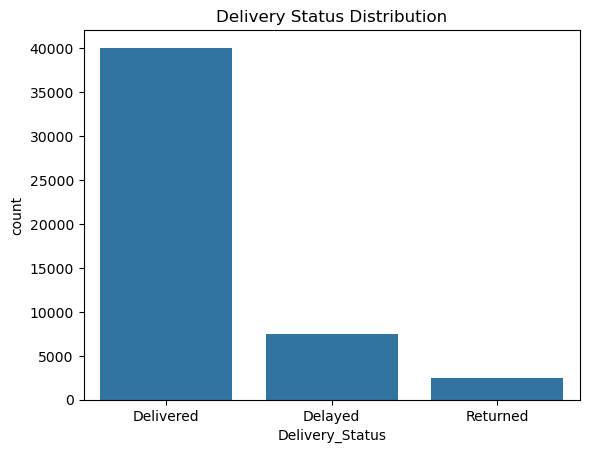

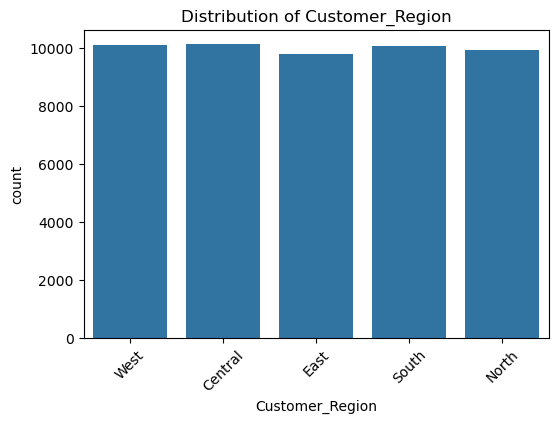

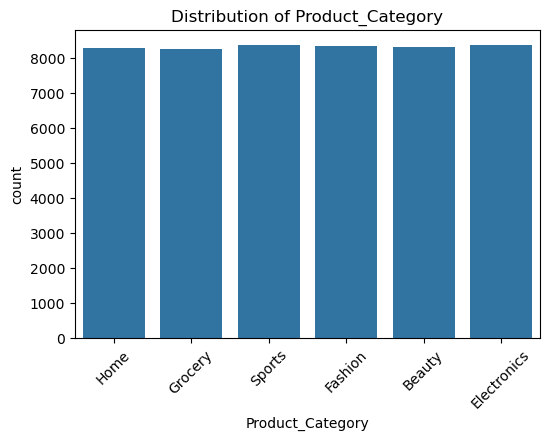

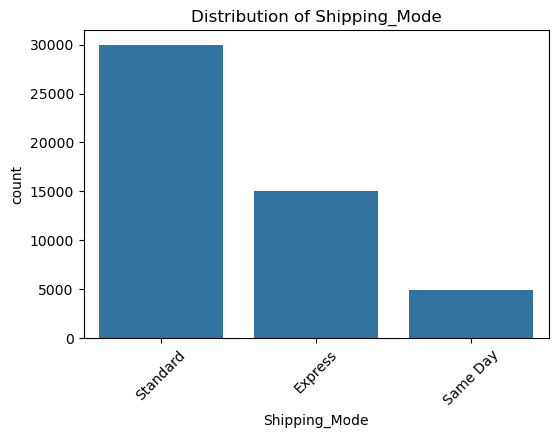

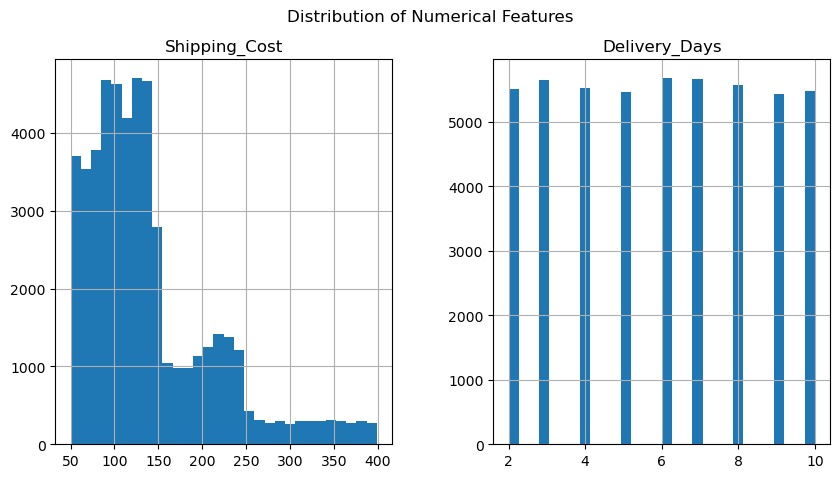

In [10]:
# Countplot for target variable
sns.countplot(x='Delivery_Status', data=df)
plt.title("Delivery Status Distribution")
plt.show()

# Countplot for categorical features
for col in ['Customer_Region','Product_Category','Shipping_Mode']:
    plt.figure(figsize=(6,4))
    sns.countplot(x=col, data=df)
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)
    plt.show()

# Histograms for numerical features
df[['Shipping_Cost','Delivery_Days']].hist(bins=30, figsize=(10,5))
plt.suptitle("Distribution of Numerical Features")
plt.show()


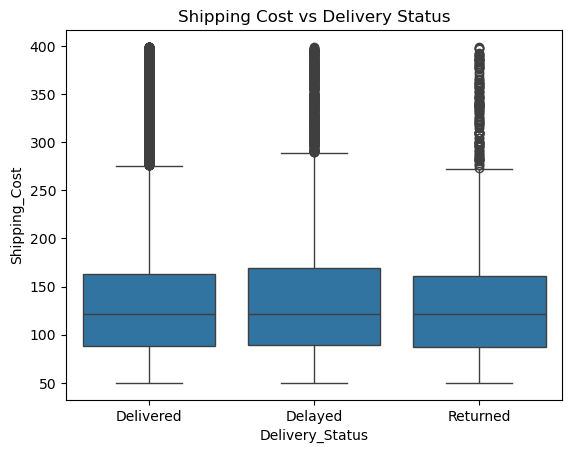

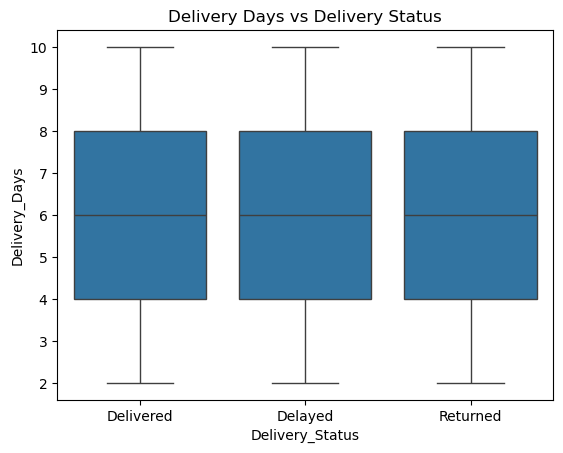

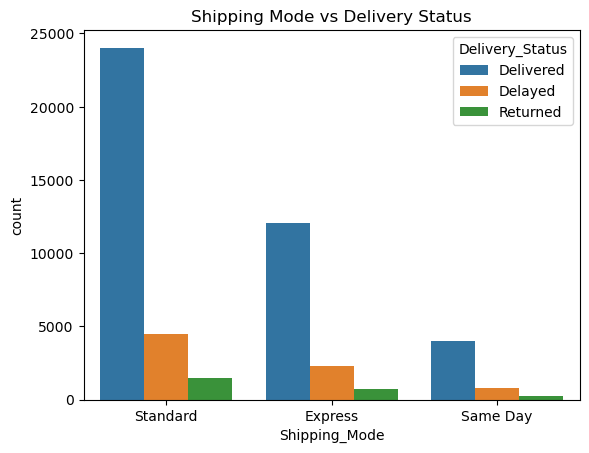

In [ ]:
# Shipping cost vs Delivery Status
sns.boxplot(x='Delivery_Status', y='Shipping_Cost', data=df)
plt.title("Shipping Cost vs Delivery Status")
plt.show()

# Delivery days vs Delivery Status
sns.boxplot(x='Delivery_Status', y='Delivery_Days', data=df)
plt.title("Delivery Days vs Delivery Status")
plt.show()

# Shipping mode vs Delivery Status
sns.countplot(x='Shipping_Mode', hue='Delivery_Status', data=df)
plt.title("Shipping Mode vs Delivery Status")
plt.show()


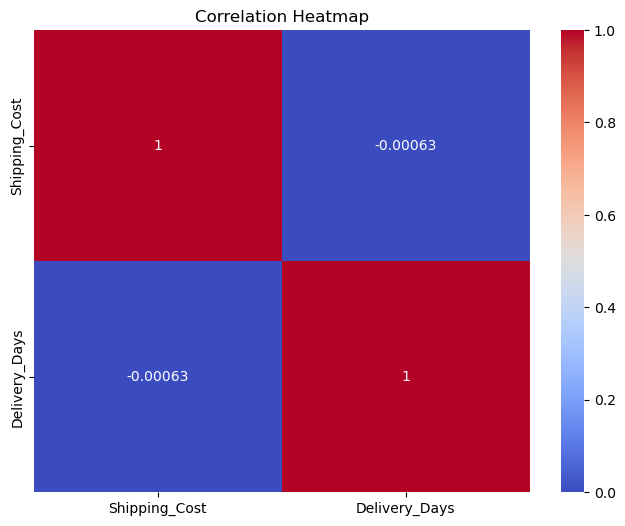

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(df[['Shipping_Cost','Delivery_Days']].corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


In [ ]:
df['Customer_Region'] = df['Customer_Region'].astype('category').cat.codes
df['Product_Category'] = df['Product_Category'].astype('category').cat.codes
df['Shipping_Mode'] = df['Shipping_Mode'].astype('category').cat.codes


In [ ]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Ship_Date'] = pd.to_datetime(df['Ship_Date'])
df['Delivery_Date'] = pd.to_datetime(df['Delivery_Date'])

# Example: order month, day of week
df['Order_Month'] = df['Order_Date'].dt.month
df['Order_DayOfWeek'] = df['Order_Date'].dt.dayofweek

In [ ]:
df.drop(columns=['Order_Date','Ship_Date','Delivery_Date'], inplace=True)

In [ ]:
df['Cost_per_Day'] = df['Shipping_Cost'] / df['Delivery_Days']


In [ ]:
df.tail(10)   


,Order_ID,Customer_Region,Product_Category,Shipping_Mode,Shipping_Cost,Delivery_Status,Delivery_Days,Order_Month,Order_DayOfWeek,Cost_per_Day
49990,OR59990,2,5,2,114,Delivered,5,5,4,22.800000
49991,OR59991,1,4,0,168,Delivered,10,2,1,16.800000
49992,OR59992,1,1,0,204,Delayed,9,4,5,22.666667
49993,OR59993,3,1,2,70,Delivered,8,6,1,8.750000
49994,OR59994,0,4,2,59,Delayed,5,7,5,11.800000
49995,OR59995,4,0,2,70,Delivered,4,9,0,17.500000
49996,OR59996,0,3,2,136,Delivered,8,2,5,17.000000
49997,OR59997,2,3,0,83,Delivered,2,6,3,41.500000
49998,OR59998,1,1,0,108,Delayed,9,9,6,12.000000
49999,OR59999,2,2,2,54,Delivered,5,8,5,10.800000


In [ ]:
df.to_csv("cleaned_ecom_shipping.csv", index=False)


In [ ]:
# Separate target from features
y = df['Delivery_Status'].astype('category').cat.codes
X = df.drop(columns=['Order_ID', 'Delivery_Status'])

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Features:", X.columns.tolist())
print("Target classes:", y.value_counts().to_dict())

X shape: (50000, 8)
y shape: (50000,)
Features: ['Customer_Region', 'Product_Category', 'Shipping_Mode', 'Shipping_Cost', 'Delivery_Days', 'Order_Month', 'Order_DayOfWeek', 'Cost_per_Day']
Target classes: {1: 40062, 0: 7505, 2: 2433}


Class balance:
1    40062
0     7505
2     2433
Name: count, dtype: int64


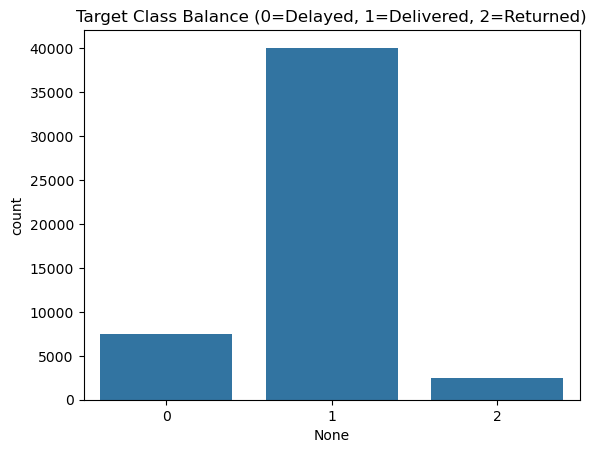

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Class balance:")
print(y.value_counts())

sns.countplot(x=y)
plt.title("Target Class Balance (0=Delayed, 1=Delivered, 2=Returned)")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (40000, 8)
Test size: (10000, 8)


In [ ]:
from sklearn.preprocessing import StandardScaler
import joblib, os

num_cols = ['Shipping_Cost','Delivery_Days',
            'Cost_per_Day','Order_Month','Order_DayOfWeek']

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])

os.makedirs("data/processed", exist_ok=True)
X_train.to_csv("data/processed/X_train.csv", index=False)
X_test.to_csv("data/processed/X_test.csv",   index=False)
y_train.to_csv("data/processed/y_train.csv", index=False)
y_test.to_csv("data/processed/y_test.csv",   index=False)
joblib.dump(scaler, "data/processed/scaler.pkl")

print("Done — feature store saved to data/processed/")

Done — feature store saved to data/processed/


In [ ]:
import os

os.makedirs("data/processed", exist_ok=True)

X_train.to_csv("data/processed/X_train.csv", index=False)
X_test.to_csv("data/processed/X_test.csv",   index=False)
y_train.to_csv("data/processed/y_train.csv", index=False)
y_test.to_csv("data/processed/y_test.csv",   index=False)

print("Saved:")
print("  data/processed/X_train.csv —", X_train.shape)
print("  data/processed/X_test.csv  —", X_test.shape)
print("  data/processed/y_train.csv —", y_train.shape)
print("  data/processed/y_test.csv  —", y_test.shape)

Saved:
  data/processed/X_train.csv — (40000, 8)
  data/processed/X_test.csv  — (10000, 8)
  data/processed/y_train.csv — (40000,)
  data/processed/y_test.csv  — (10000,)


In [ ]:
import joblib

joblib.dump(scaler, "data/processed/scaler.pkl")

print("Saved: data/processed/scaler.pkl")
print("Scaler type:", type(scaler))

Saved: data/processed/scaler.pkl
Scaler type: <class 'sklearn.preprocessing._data.StandardScaler'>


In [ ]:
import os
print("Files saved at:")
print(os.path.abspath("data/processed/"))
print()
print("Files inside:")
for f in os.listdir("data/processed/"):
    print(" ", f)

Files saved at:
C:\Users\Vivek Kumar Singh\data\processed

Files inside:
  scaler.pkl
  X_test.csv
  X_train.csv
  y_test.csv
  y_train.csv


In [ ]:
import shutil
shutil.move(
    r"C:\Users\Vivek Kumar Singh\data",
    r"C:\Users\Vivek Kumar Singh\OneDrive\Desktop\data"
)
print("Moved to Desktop")

Moved to Desktop
